###Installation

###Unsloth

In [1]:
import unsloth

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
🦥 Unsloth Zoo will now patch everything to make training faster!


In [2]:
from unsloth import FastVisionModel    #FastLanguageModel for LLM

model, tokenizer = FastVisionModel.from_pretrained(
    "unsloth/Qwen3.5-4B",
    load_in_4bit=False,
    use_gradient_checkpointing="unsloth"
)

==((====))==  Unsloth 2026.4.5: Fast Qwen3_5 patching. Transformers: 5.5.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.10.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: Using float16 precision for qwen3_5 won't work! Using float32.
Unsloth: QLoRA and full finetuning all not selected. Switching to 16bit LoRA.


model.safetensors.index.json: 0.00B [00:00, ?B/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

The fast path is not available because one of the required library is not installed. Falling back to torch implementation. To install follow https://github.com/fla-org/flash-linear-attention#installation and https://github.com/Dao-AILab/causal-conv1d


Loading weights:   0%|          | 0/723 [00:00<?, ?it/s]

processor_config.json: 0.00B [00:00, ?B/s]

chat_template.jinja: 0.00B [00:00, ?B/s]

preprocessor_config.json:   0%|          | 0.00/336 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.json:   0%|          | 0.00/20.0M [00:00<?, ?B/s]

video_preprocessor_config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

We now add LoRA adapters for parameter efficient finetuning - this allows us to only efficiently train 1% of all parameters.

In [3]:
model.named_modules()

<generator object Module.named_modules at 0x7817d2f82df0>

In [4]:
model = FastVisionModel.get_peft_model(
    model,
    finetune_vision_layers=True,
    finetune_language_layers=True,
    finetune_attention_modules=True,
    finetune_mlp_modules=True,

    r = 16,
    lora_alpha=16,
    lora_dropout=0,
    bias="none",
    use_rslora=False,    # Rank Stabalized LORA
    loftq_config = None, # And LoftQ


    random_state=2003,
)

Unsloth: Making `model.base_model.model.model.visual` require gradients


###Data Preparation

We'll be using a sampled dataset of handwritten maths formulas. The goal is to convert these images into a computer readable form - ie in LaTeX form, so we can render it. This can be very useful for complex formulas.

You can access the dataset [here](https://huggingface.co/datasets/unsloth/LaTeX_OCR)

In [5]:
from datasets import load_dataset

dataset = load_dataset("unsloth/LaTeX_OCR", split= "train")

README.md:   0%|          | 0.00/519 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/344M [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/38.2M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/68686 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7632 [00:00<?, ? examples/s]

In [6]:
dataset

Dataset({
    features: ['image', 'text'],
    num_rows: 68686
})

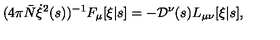

In [7]:
dataset[5]["image"]

In [8]:
dataset[5]["text"]

'( 4 \\pi { \\bar { N } } \\dot { \\xi } ^ { 2 } ( s ) ) ^ { - 1 } F _ { \\mu } [ \\xi | s ] = - { \\cal D } ^ { \\nu } ( s ) L _ { \\mu \\nu } [ \\xi | s ] ,'

Render the LaTeX

In [9]:
from IPython.display import Math, display, Latex

latex = dataset[5]["text"]
display(Math(latex))

<IPython.core.display.Math object>

####**To format the dataset, all vision finetuning tasks should be formatted as follows:**

```python
[
  {
    "role":"user",
    "content": [{"type":"text", "text":Q}, {"type":"image", "image": image}]
  },
  {
    "role":"assistant",
    "content": [{"type":"text", "text":A}]
  }
]
```

In [10]:
instruction = "Write the LaTeX representation for this image."

def convert_to_conversation(sample):
    conversation = [
        { "role": "user",
          "content" : [
            {"type" : "text",  "text"  : instruction},
            {"type" : "image", "image" : sample["image"]} ]
        },
        { "role" : "assistant",
          "content" : [
            {"type" : "text",  "text"  : sample["text"]} ]
        },
    ]
    return { "messages" : conversation }
pass

Let's convert the dataset now

In [11]:
converted_dataset = [convert_to_conversation(sample) for sample in dataset]

In [12]:
converted_dataset[0]

{'messages': [{'role': 'user',
   'content': [{'type': 'text',
     'text': 'Write the LaTeX representation for this image.'},
    {'type': 'image',
     'image': <PIL.PngImagePlugin.PngImageFile image mode=RGB size=160x40>}]},
  {'role': 'assistant',
   'content': [{'type': 'text',
     'text': '{ \\frac { N } { M } } \\in { \\bf Z } , { \\frac { M } { P } } \\in { \\bf Z } , { \\frac { P } { Q } } \\in { \\bf Z }'}]}]}

Before we do any finetuning, let's see what the model outputs for the first example

In [13]:
FastVisionModel.for_inference(model)    #Enable Inference

image = dataset[5]["image"]
instruction = "Write the LaTeX representation for this image."

messages = [{
    "role": "user",
    "content": [
        {"type": "image", "image": image},
        {"type": "text", "text": instruction}
    ]
}]

input_text = tokenizer.apply_chat_template(messages, add_generation_prompt=True)

inputs = tokenizer(
    image,
    input_text,
    add_special_tokens=False,
    return_tensors="pt",
).to("cuda")

from transformers import TextStreamer
text_streamer = TextStreamer(tokenizer, skip_prompt=True)
_ = model.generate(**inputs, streamer=text_streamer, max_new_tokens=128, use_cache=True, min_p=0.1, temperature=1.5)

 $$( 4 \pi \bar { N } \dot { \xi } ^ { 2 } ( s ) ) ^ { - 1 } F _ { \mu } [ \xi | s ] = - \mathcal { D } ^ { \nu } ( s ) L _ { \mu \nu } [ \xi | s ] ,$$<|im_end|>
<|endoftext|>


###Train the model

In [14]:
from unsloth.trainer import UnslothVisionDataCollator
from trl import SFTTrainer, SFTConfig

FastVisionModel.for_training(model) # Enable for training!

trainer = SFTTrainer(
    model = model,
    tokenizer = tokenizer,
    data_collator = UnslothVisionDataCollator(model, tokenizer), # Must use!
    train_dataset = converted_dataset,
    args = SFTConfig(
        per_device_train_batch_size = 2,
        gradient_accumulation_steps = 4,
        warmup_steps = 5,
        max_steps = 15,
        # num_train_epochs = 1, # Set this instead of max_steps for full training runs
        learning_rate = 2e-4,
        logging_steps = 1,
        optim = "adamw_8bit",
        weight_decay = 0.001,
        lr_scheduler_type = "linear",
        seed = 3407,
        output_dir = "outputs",
        report_to = "none",     # For Weights and Biases

        # You MUST put the below items for vision finetuning:
        remove_unused_columns = False,
        dataset_text_field = "",
        dataset_kwargs = {"skip_prepare_dataset": True},
        max_length = 2048,
    ),
)

Unsloth: Model does not have a default image size - using 512
Unsloth: Switching to float32 training since model cannot work with float16


In [15]:
import torch
# @title Show current memory stats
gpu_stats = torch.cuda.get_device_properties(0)
start_gpu_memory = round(torch.cuda.max_memory_reserved() / 1024 / 1024 / 1024, 3)
max_memory = round(gpu_stats.total_memory / 1024 / 1024 / 1024, 3)
print(f"GPU = {gpu_stats.name}. Max memory = {max_memory} GB.")
print(f"{start_gpu_memory} GB of memory reserved.")

GPU = Tesla T4. Max memory = 14.563 GB.
9.68 GB of memory reserved.


In [16]:
trainer_stats = trainer.train()

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 248046}.
==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 68,686 | Num Epochs = 1 | Total steps = 15
O^O/ \_/ \    Batch size per device = 2 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (2 x 4 x 1) = 8
 "-____-"     Trainable parameters = 38,756,352 of 4,578,021,888 (0.85% trained)


Unsloth: Will smartly offload gradients to save VRAM!


Step,Training Loss
1,0.699746
2,0.861523
3,0.662139
4,0.451325
5,0.363735
6,0.342157
7,0.232340
8,0.131754
9,0.088707
10,0.097106


In [17]:
import torch
# @title Show final memory and time stats
used_memory = round(torch.cuda.max_memory_reserved() / 1024 / 1024 / 1024, 3)
used_memory_for_lora = round(used_memory - start_gpu_memory, 3)
used_percentage = round(used_memory / max_memory * 100, 3)
lora_percentage = round(used_memory_for_lora / max_memory * 100, 3)
print(f"{trainer_stats.metrics['train_runtime']} seconds used for training.")
print(
    f"{round(trainer_stats.metrics['train_runtime']/60, 2)} minutes used for training."
)
print(f"Peak reserved memory = {used_memory} GB.")
print(f"Peak reserved memory for training = {used_memory_for_lora} GB.")
print(f"Peak reserved memory % of max memory = {used_percentage} %.")
print(f"Peak reserved memory for training % of max memory = {lora_percentage} %.")

253.8481 seconds used for training.
4.23 minutes used for training.
Peak reserved memory = 9.705 GB.
Peak reserved memory for training = 0.025 GB.
Peak reserved memory % of max memory = 66.641 %.
Peak reserved memory for training % of max memory = 0.172 %.


###Inference Time!

In [18]:
FastVisionModel.for_inference(model) # Enable for inference!

image = dataset[5]["image"]
instruction = "Write the LaTeX representation for this image."

messages = [
    {"role": "user", "content": [
        {"type": "image"},
        {"type": "text", "text": instruction}
    ]}
]
input_text = tokenizer.apply_chat_template(messages, add_generation_prompt = True)
inputs = tokenizer(
    image,
    input_text,
    add_special_tokens = False,
    return_tensors = "pt",
).to("cuda")

from transformers import TextStreamer
text_streamer = TextStreamer(tokenizer, skip_prompt = True)
_ = model.generate(**inputs, streamer = text_streamer, max_new_tokens = 128,
                   use_cache = True, temperature = 1.5, min_p = 0.1)

( 4 \pi \bar { N } \dot { \xi } ^ { 2 } ( s ) ) ^ { - 1 } F _ { \mu } [ \xi | s ] = - \mathcal { D } ^ { \nu } ( s ) L _ { \mu \nu } [ \xi | s ] ,<|im_end|>


In [19]:
dataset[5]["text"]

'( 4 \\pi { \\bar { N } } \\dot { \\xi } ^ { 2 } ( s ) ) ^ { - 1 } F _ { \\mu } [ \\xi | s ] = - { \\cal D } ^ { \\nu } ( s ) L _ { \\mu \\nu } [ \\xi | s ] ,'

### Saving and Loading the finetuned Model

To save the final model as LoRA adapters, either use Hugging Face's `push_to_hub` for an online save or `save_pretrained` for a local save.

**[NOTE]** This ONLY saves the LoRA adapters

In [20]:
model.save_pretrained("qwen_lora")  # Local saving
tokenizer.save_pretrained("qwen_lora")
# model.push_to_hub("your_name/qwen_lora", token = "YOUR_HF_TOKEN") # Online saving
# tokenizer.push_to_hub("your_name/qwen_lora", token = "YOUR_HF_TOKEN") # Online saving

['qwen_lora/processor_config.json']

Now, we use the saved model for inference

In [22]:
from unsloth import FastVisionModel

model, tokenizer = FastVisionModel.from_pretrained(
    model_name="qwen_lora",
    load_in_4bit=True,
)
FastVisionModel.for_inference(model)


image = dataset[8]["image"]
instruction = "Write LaTeX representation for this image."

messages = [
    {"role": "user", "content": [
        {"type": "image"},
        {"type": "text", "text": instruction}
    ]}
]

==((====))==  Unsloth 2026.4.5: Fast Qwen3_5 patching. Transformers: 5.5.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.10.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: Using float16 precision for qwen3_5 won't work! Using float32.


ValueError: Some modules are dispatched on the CPU or the disk. Make sure you have enough GPU RAM to fit the quantized model. If you want to dispatch the model on the CPU or the disk while keeping these modules in 32-bit, you need to set `llm_int8_enable_fp32_cpu_offload=True` and pass a custom `device_map` to `from_pretrained`. Check https://huggingface.co/docs/transformers/main/en/main_classes/quantization#offload-between-cpu-and-gpu for more details. 

In [24]:
input_text = tokenizer.apply_chat_template(messages, add_generation_prompt=True)

inputs = tokenizer (
    image,
    input_text,
    add_special_tokens=False,
    return_tensors="pt"
).to("cuda")

from transformers import TextStreamer

text_streamer = TextStreamer(tokenizer, skip_prompt=True)
_ = model.generate(**inputs, streamer=text_streamer, max_new_tokens=128, use_cache=True, temperature=1.5, min_p=0.1)

f _ { g } ^ { A } = V _ { 1 1 } \sum _ { ( n ^ { 1 } , n ^ { 2 } ) \neq ( 0 , 0 ) } \left( n ^ { I } g _ { I J } n ^ { J } \right) ^ { - 3 / 2 } \ , \ \ V _ { 1 1 } = \sqrt { \operatorname * { d e t } g _ { I J } }<|im_end|>
<|endoftext|>
